# YESNO Spoken-Word Classification

**Amirkabir University of Technology**  
**Department of Computer Engineering**  
**Digital Speech Processing — Dr. Khaloei**  
**Student:** Baraa Atmeesh  
**Student ID:** 403131113  
**Mini Task: Audio Classification**

## Aim
I trained five classifiers to distinguish the Hebrew words *ken* (YES) and *lo* (NO). I used the original YESNO recordings through `torchaudio.datasets.YESNO`. I kept the test recordings separate from the training recordings so that different words from the same WAV file could not appear in both sets.

## 1. Setup
I imported the signal-processing and machine-learning libraries. The notebook downloads YESNO automatically when the recordings are not already in the `data` directory. Google Colab needs an Internet connection for the first download.

In [3]:
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("torchaudio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchaudio"])

from pathlib import Path
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torchaudio
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks, stft
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Image

ROOT = Path.cwd()
for name in ["data", "results", "figures"]:
    (ROOT/name).mkdir(exist_ok=True)
print("torchaudio version:", torchaudio.__version__)
print("Working directory:", ROOT)


torchaudio version: 2.10.0+cpu
Working directory: /mnt/data/Baraa_YesNo_Final


## 2. Listening to the data and checking its labels
Each recording contains eight binary labels. I first checked the sample rate and class counts, then plotted a waveform and spectrogram to understand where the words occur.

Recordings: 60


First recording: torch.Size([1, 50800]) sample rate: 8000 labels: [0, 0, 0, 0, 1, 1, 1, 1]


All word labels: 480 YES: 251 NO: 229


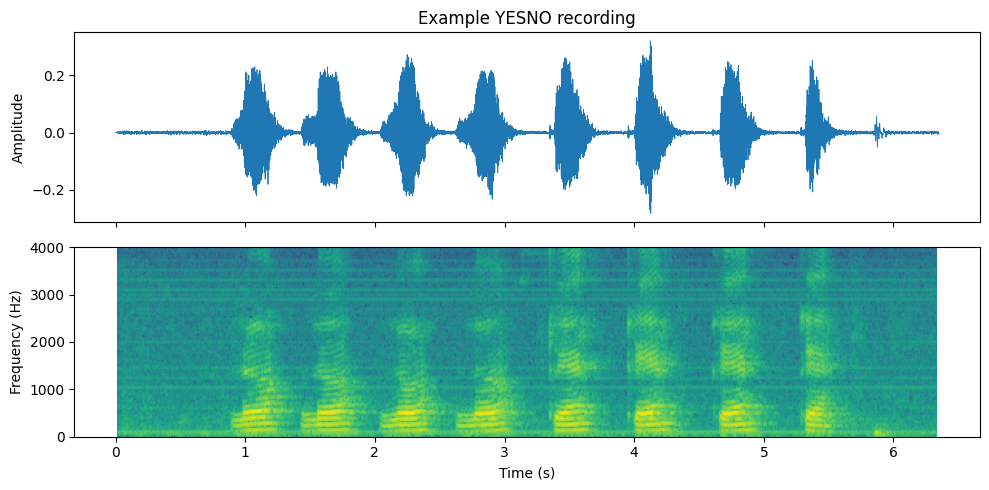

In [5]:
dataset = torchaudio.datasets.YESNO(root=str(ROOT/"data"), url="https://www.openslr.org/resources/1/waves_yesno.tar.gz", download=True)
print("Recordings:", len(dataset))
try:
    waveform, sample_rate, labels = dataset[0]
except (RuntimeError, ImportError) as exc:
    if "torchcodec" in str(exc).lower():
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchcodec"])
        waveform, sample_rate, labels = dataset[0]
    else:
        raise
print("First recording:", waveform.shape, "sample rate:", sample_rate, "labels:", labels)
all_labels = [label for i in range(len(dataset)) for label in dataset[i][2]]
print("All word labels:", len(all_labels), "YES:", sum(all_labels), "NO:", len(all_labels)-sum(all_labels))
signal = waveform[0].numpy()
fig, axes = plt.subplots(2,1,figsize=(10,5),sharex=True)
axes[0].plot(np.arange(len(signal))/sample_rate,signal,lw=.6)
axes[0].set(ylabel="Amplitude",title="Example YESNO recording")
axes[1].specgram(signal,Fs=sample_rate,NFFT=256,noverlap=176,cmap="viridis")
axes[1].set(xlabel="Time (s)",ylabel="Frequency (Hz)")
fig.tight_layout()
fig.savefig(ROOT/"figures"/"waveform_spectrogram.png",dpi=175)
plt.show()


## 3. Segmenting the spoken words
I measured short-time RMS energy in 25 ms windows with a 10 ms hop. I detected energy peaks at least 320 ms apart and used low-energy valleys as word boundaries. When more than eight peaks appeared, I retained the eight strongest only when their energy gap from the extra peaks was at least 7 dB. I did not invent a missing word when fewer than eight peaks were found.

In [7]:
def frame_rms(signal, frame_length=200, hop=80, sample_rate=8000):
    signal = np.asarray(signal, dtype=np.float64)
    if len(signal) < frame_length:
        raise ValueError("Audio is shorter than the analysis frame")
    frames = np.lib.stride_tricks.sliding_window_view(signal, frame_length)[::hop]
    rms = np.sqrt(np.mean(frames ** 2, axis=1) + 1e-12)
    times = np.arange(len(rms)) * hop / sample_rate
    return rms, times


def segment_words(signal, sample_rate=8000, expected_words=8):
    if sample_rate != 8000:
        raise ValueError(f"Expected 8000 Hz, received {sample_rate}")
    rms, times = frame_rms(signal, sample_rate=sample_rate)
    log_energy = gaussian_filter1d(20 * np.log10(rms + 1e-8), sigma=1.6)
    floor = float(np.percentile(log_energy, 15))
    candidates, properties = find_peaks(
        log_energy, distance=32, prominence=5.0, height=floor + 7.0
    )
    reason = "accepted"
    if len(candidates) < expected_words:
        reason = f"Only {len(candidates)} energy peaks were detected"
        return None, {"reason": reason, "energy": log_energy, "times": times, "peaks": candidates}
    if len(candidates) > expected_words:
        levels = log_energy[candidates]
        strongest = np.argsort(levels)[::-1]
        margin_db = float(levels[strongest[expected_words-1]] - levels[strongest[expected_words]])
        if margin_db < 7.0:
            reason = f"Extra peaks cannot be separated reliably (gap {margin_db:.1f} dB)"
            return None, {"reason": reason, "energy": log_energy, "times": times, "peaks": candidates}
        candidates = np.sort(candidates[strongest[:expected_words]])
        reason = f"accepted after rejecting weaker peaks (margin {margin_db:.1f} dB)"
    peaks = np.sort(candidates)
    boundaries = [0]
    for a, b in zip(peaks[:-1], peaks[1:]):
        boundaries.append(int(a + np.argmin(log_energy[a:b+1])))
    boundaries.append(len(log_energy) - 1)
    spans = []
    for i, p in enumerate(peaks):
        lo, hi = boundaries[i], boundaries[i+1]
        local_floor = float(np.percentile(log_energy[lo:hi+1], 10))
        threshold = local_floor + 0.27 * (log_energy[p] - local_floor)
        region = log_energy[lo:hi+1] >= threshold
        j = p - lo
        left = right = j
        while left > 0 and region[left-1]:
            left -= 1
        while right < len(region)-1 and region[right+1]:
            right += 1
        start = max(0, int((lo + left)*80 - 240))
        end = min(len(signal), int((lo + right)*80 + 200 + 240))
        duration = (end - start) / sample_rate
        if not (0.12 <= duration <= 0.85):
            reason = f"Suspicious word {i+1} duration: {duration:.3f} s"
            return None, {"reason": reason, "energy": log_energy, "times": times, "peaks": peaks}
        spans.append((start, end))
    if any(spans[i][1] > spans[i+1][0] + int(.10*sample_rate) for i in range(len(spans)-1)):
        reason = "Adjacent word regions overlap too much"
        return None, {"reason": reason, "energy": log_energy, "times": times, "peaks": peaks}
    return spans, {"reason": reason, "energy": log_energy, "times": times, "peaks": peaks}




Number of detected segments: 8
Segmentation status: accepted after rejecting weaker peaks (margin 13.8 dB)


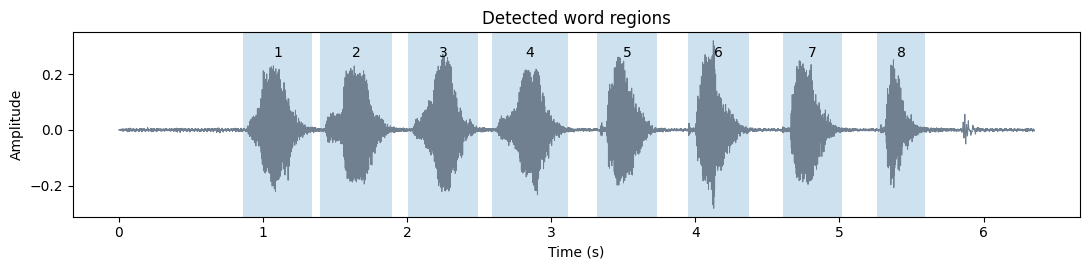

In [8]:
segments, details = segment_words(signal, sample_rate)
print("Number of detected segments:", len(segments) if segments else 0)
print("Segmentation status:", details["reason"])
fig, ax = plt.subplots(figsize=(11,2.8))
ax.plot(np.arange(len(signal))/sample_rate,signal,lw=.7,color="slategray")
if segments:
    for idx,(start,end) in enumerate(segments,1):
        ax.axvspan(start/sample_rate,end/sample_rate,alpha=.22)
        ax.text((start+end)/(2*sample_rate),.75*ax.get_ylim()[1],str(idx),ha="center")
ax.set(xlabel="Time (s)",ylabel="Amplitude",title="Detected word regions")
fig.tight_layout()
plt.show()


## 4. Extracting 40 spectral features
Instead of using MFCCs, I extracted the mean and standard deviation of 16 log-frequency energy bands and four spectral descriptors: centroid, rolloff, spectral flux, and zero-crossing rate. This produced a 40-dimensional feature vector for each detected word.

In [10]:
def spectral_features(signal, sample_rate=8000):
    signal = np.asarray(signal, dtype=np.float64)
    if len(signal) < 256:
        signal = np.pad(signal, (0, 256 - len(signal)))
    freqs, _, transform = stft(signal, fs=sample_rate, window="hann",
                                nperseg=256, noverlap=176, nfft=256,
                                boundary=None, padded=False)
    power = np.abs(transform) ** 2 + 1e-12
    band_edges = np.geomspace(100, 4000, 17)
    bands = []
    for j in range(16):
        inside = (freqs >= band_edges[j]) & (
            freqs < band_edges[j+1] if j < 15 else freqs <= band_edges[j+1])
        bands.append(np.log(np.mean(power[inside], axis=0) + 1e-12))
    bands = np.asarray(bands)
    magnitude = np.sqrt(power)
    total_magnitude = np.sum(magnitude, axis=0) + 1e-12
    centroid = np.sum(freqs[:,None]*magnitude, axis=0) / total_magnitude / 4000
    cumulative = np.cumsum(power, axis=0)
    rolloff = freqs[np.argmax(cumulative >= 0.85*np.sum(power,axis=0),axis=0)] / 4000
    normalized = magnitude / total_magnitude
    flux = np.r_[0, np.linalg.norm(np.diff(normalized,axis=1),axis=0)]
    framed = np.lib.stride_tricks.sliding_window_view(signal,256)[::80]
    zcr = np.mean(np.diff(np.signbit(framed),axis=1)!=0,axis=1)
    n_frames = len(centroid)
    zcr = zcr[:n_frames] if len(zcr)>=n_frames else np.pad(zcr,(0,n_frames-len(zcr)),mode="edge")
    tracks = np.vstack([bands,centroid,rolloff,flux,zcr])
    features = np.r_[np.mean(tracks,axis=1),np.std(tracks,axis=1)]
    if features.shape != (40,) or not np.isfinite(features).all():
        raise ValueError("Feature extraction produced an invalid vector")
    return features


In [11]:
if segments:
    example_features = spectral_features(signal[segments[0][0]:segments[0][1]], sample_rate)
    print("Features per word:", len(example_features))
    print("First eight feature values:", np.round(example_features[:8], 3))


Features per word: 40
First eight feature values: [-10.688 -11.543 -13.412 -10.65  -10.592 -11.176 -10.761 -11.187]


## 5. Training and comparing five classifiers
I separated the data by recording using `GroupShuffleSplit` (25% test). I compared a linear SVM, an MLP neural network, Extra Trees, distance-weighted KNN, and Gaussian Naive Bayes. The four-fold grouped cross-validation runs only within the training recordings. Each model includes a fitted training-only scaler.

I saved the numerical results and predictions so that I could check the report against the actual model output.

In [13]:
def show_segmentation(signal, sample_rate, spans, info, filename, output):
    fig, ax = plt.subplots(figsize=(11,2.9))
    ax.plot(np.arange(len(signal))/sample_rate,signal,color="#35445c",lw=.65)
    if spans is not None:
        for i,(a,b) in enumerate(spans):
            ax.axvspan(a/sample_rate,b/sample_rate,color="#007f86" if i%2==0 else "#d38a28",alpha=.24)
            ax.text((a+b)/(2*sample_rate),.85*ax.get_ylim()[1],str(i+1),ha="center",fontsize=8)
    else:
        ax.text(.02,.93,info["reason"],transform=ax.transAxes,color="#a32020",va="top")
    ax.set(title=filename,xlabel="Time (s)",ylabel="Amplitude")
    fig.tight_layout()
    fig.savefig(output,dpi=145)
    plt.close(fig)


def bootstrap_group_accuracy(labels, predicted, groups, repeats=1000, seed=2026):
    rng=np.random.default_rng(seed)
    unique=np.unique(groups)
    group_indexes={k:np.flatnonzero(groups==k) for k in unique}
    samples=[]
    for _ in range(repeats):
        chosen=rng.choice(unique,size=len(unique),replace=True)
        indices=np.concatenate([group_indexes[k] for k in chosen])
        samples.append(accuracy_score(labels[indices],predicted[indices]))
    return np.quantile(samples,[.025,.975])



def main():
    for folder in ["data","results","figures"]:
        (ROOT/folder).mkdir(exist_ok=True)
    review=ROOT/"figures"/"segmentation_review"
    review.mkdir(exist_ok=True)
    dataset=torchaudio.datasets.YESNO(root=str(ROOT/"data"),
             url="https://www.openslr.org/resources/1/waves_yesno.tar.gz", download=True)
    audio_files=sorted((ROOT/"data"/"waves_yesno").glob("*.wav"))
    if len(dataset)!=len(audio_files):
        raise RuntimeError("Dataset list and audio files do not match")
    print(f"YESNO loaded through torchaudio.datasets.YESNO: {len(dataset)} files")
    X,y,groups,identifiers=[],[],[],[]
    rejected=[]; accepted=[]
    for file_index in range(len(dataset)):
        waveform,sample_rate,labels=dataset[file_index]
        filename=audio_files[file_index].name
        expected=[int(part) for part in audio_files[file_index].stem.split("_")]
        if list(labels)!=expected:
            raise ValueError(f"Label order does not match filename: {filename}")
        signal=waveform.mean(dim=0).numpy()
        spans,info=segment_words(signal,sample_rate)
        show_segmentation(signal,sample_rate,spans,info,filename,review/f"{file_index:02d}.png")
        if spans is None:
            rejected.append({"file":filename,"reason":info["reason"]})
            continue
        if len(spans)!=len(labels):
            raise ValueError(f"Alignment mismatch in {filename}")
        accepted.append(filename)
        for word_index,((start,end),label) in enumerate(zip(spans,labels),1):
            X.append(spectral_features(signal[start:end],sample_rate))
            y.append(int(label));groups.append(file_index)
            identifiers.append(f"{filename}:word{word_index}")
    pd.DataFrame(rejected,columns=["file","reason"]).to_csv(ROOT/"results"/"rejected_recordings.csv",index=False)
    X=np.asarray(X);y=np.asarray(y);groups=np.asarray(groups)
    np.savez_compressed(ROOT/"results"/"features.npz",X=X,y=y,groups=groups,ids=identifiers)
    assert len(X)==len(y)==len(groups) and X.shape[1]==40
    if len(np.unique(groups))<16:
        raise RuntimeError("Not enough reliably segmented recordings")
    train_idx,test_idx=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=2026).split(X,y,groups))
    assert set(groups[train_idx]).isdisjoint(set(groups[test_idx]))
    cv=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=2026)
    models={
        "Linear SVM":make_pipeline(StandardScaler(),SVC(kernel="linear",C=0.5)),
        "MLP Neural Network":make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(32,16),alpha=.01,max_iter=1100,random_state=2026)),
        "Extra Trees":make_pipeline(StandardScaler(),ExtraTreesClassifier(n_estimators=160,min_samples_leaf=2,random_state=2026,n_jobs=-1)),
        "KNN (k=7)":make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=7,weights="distance")),
        "Gaussian Naive Bayes":make_pipeline(StandardScaler(),GaussianNB(var_smoothing=1e-8))
    }
    scores=[]; predictions={}
    for name,model in models.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore",category=UserWarning)
            cv_scores=cross_val_score(model,X[train_idx],y[train_idx],groups=groups[train_idx],cv=cv,scoring="balanced_accuracy")
            model.fit(X[train_idx],y[train_idx])
        predicted=model.predict(X[test_idx]);predictions[name]=predicted
        precision,recall,f1,_=precision_recall_fscore_support(y[test_idx],predicted,average="binary",pos_label=1,zero_division=0)
        lo,hi=bootstrap_group_accuracy(y[test_idx],predicted,groups[test_idx])
        scores.append({"Model":name,"CV balanced accuracy mean":float(np.mean(cv_scores)),
         "CV balanced accuracy std":float(np.std(cv_scores,ddof=1)),
         "Test accuracy":accuracy_score(y[test_idx],predicted),
         "Test balanced accuracy":balanced_accuracy_score(y[test_idx],predicted),
         "YES precision":precision,"YES recall":recall,"YES F1":f1,
         "Errors":int(np.sum(predicted!=y[test_idx])),"Accuracy 95pct bootstrap low":lo,
         "Accuracy 95pct bootstrap high":hi})
        print(f"{name:23s} Test accuracy: {scores[-1]['Test accuracy']:.4f}; train CV balanced accuracy: {cv_scores.mean():.4f}")
    table=pd.DataFrame(scores).sort_values("Test balanced accuracy",ascending=False)
    table.to_csv(ROOT/"results"/"model_comparison.csv",index=False,float_format="%.6f")
    pd.DataFrame({"word":np.asarray(identifiers)[test_idx],"recording_group":groups[test_idx],
      "true_label":y[test_idx],**{f"prediction_{i+1}":p for i,p in enumerate(predictions.values())}}).to_csv(ROOT/"results"/"test_predictions.csv",index=False)
    meta={"recordings_total":len(dataset),"recordings_accepted":len(accepted),
      "recordings_excluded":len(rejected),"words_used":len(y),"yes_words":int(np.sum(y)),
      "no_words":int(len(y)-np.sum(y)),"train_words":len(train_idx),"test_words":len(test_idx),
      "train_recordings":len(np.unique(groups[train_idx])),"test_recordings":len(np.unique(groups[test_idx])),
      "feature_dimension":X.shape[1],"cv_folds":4,"seed":2026,
      "segmentation_note":"Energy-peak selection was checked against visualization; the unresolved recording was excluded."}
    (ROOT/"results"/"run_metadata.json").write_text(json.dumps(meta,indent=2),encoding="utf-8")
    fig,ax=plt.subplots(figsize=(9,4.2))
    ax.barh(table["Model"],table["Test balanced accuracy"],color="#197e88")
    ax.set(xlim=(0,1.08),xlabel="Test balanced accuracy",title="YESNO: independent recording test set")
    ax.invert_yaxis()
    for row,v in enumerate(table["Test balanced accuracy"]):
        ax.text(min(1.02,v+.012),row,f"{v:.3f}",va="center",fontsize=9)
    fig.tight_layout();fig.savefig(ROOT/"figures"/"model_comparison.png",dpi=175);plt.close(fig)
    fig,axes=plt.subplots(1,len(models),figsize=(16,3.7))
    for ax,(name,pred) in zip(axes,predictions.items()):
        matrix=confusion_matrix(y[test_idx],pred,labels=[0,1])
        ConfusionMatrixDisplay(matrix,display_labels=["NO","YES"]).plot(ax=ax,cmap="Blues",colorbar=False)
        ax.set_title(name,fontsize=9)
    fig.tight_layout();fig.savefig(ROOT/"figures"/"confusion_matrices.png",dpi=170);plt.close(fig)
    ablations=[]
    for subset,cols in [("Log-frequency band statistics",np.arange(32)),
                        ("Spectral descriptors only",np.arange(32,40)),("All 40 features",np.arange(40))]:
        for name,base in [("Linear SVM",SVC(kernel="linear",C=.5)),
                          ("Extra Trees",ExtraTreesClassifier(n_estimators=160,min_samples_leaf=2,random_state=2026,n_jobs=-1))]:
            model=make_pipeline(StandardScaler(),base)
            model.fit(X[train_idx][:,cols],y[train_idx]);pred=model.predict(X[test_idx][:,cols])
            ablations.append({"Feature set":subset,"Model":name,
                "Test balanced accuracy":balanced_accuracy_score(y[test_idx],pred)})
    ablation_table=pd.DataFrame(ablations)
    ablation_table.to_csv(ROOT/"results"/"feature_ablation.csv",index=False)
    fig,ax=plt.subplots(figsize=(8.8,4.3))
    ablation_table.pivot(index="Feature set",columns="Model",values="Test balanced accuracy").plot(
        kind="bar",ax=ax,rot=6,ylim=(0,1.09),color=["#197e88","#e8a650"])
    ax.set(title="Feature comparison on the same test recordings",xlabel="",ylabel="Balanced accuracy")
    fig.tight_layout();fig.savefig(ROOT/"figures"/"feature_ablation.png",dpi=175);plt.close(fig)
    print("Saved new results, plots and segmentation review images")
    print(json.dumps(meta,indent=2))



YESNO loaded through torchaudio.datasets.YESNO: 60 files


Linear SVM              Test accuracy: 1.0000; train CV balanced accuracy: 0.9969


MLP Neural Network      Test accuracy: 1.0000; train CV balanced accuracy: 0.9938


Extra Trees             Test accuracy: 0.9917; train CV balanced accuracy: 0.9906


KNN (k=7)               Test accuracy: 0.9917; train CV balanced accuracy: 0.9938


Gaussian Naive Bayes    Test accuracy: 0.9917; train CV balanced accuracy: 0.9906


Saved new results, plots and segmentation review images
{
  "recordings_total": 60,
  "recordings_accepted": 59,
  "recordings_excluded": 1,
  "words_used": 472,
  "yes_words": 249,
  "no_words": 223,
  "train_words": 352,
  "test_words": 120,
  "train_recordings": 44,
  "test_recordings": 15,
  "feature_dimension": 40,
  "cv_folds": 4,
  "seed": 2026,
  "segmentation_note": "Energy-peak selection was checked against visualization; the unresolved recording was excluded."
}


,Model,CV balanced accuracy mean,CV balanced accuracy std,Test accuracy,Test balanced accuracy,YES precision,YES recall,YES F1,Errors,Accuracy 95pct bootstrap low,Accuracy 95pct bootstrap high
0,Linear SVM,0.996875,0.00625,1.000000,1.000000,1.0,1.000000,1.000000,0,1.000,1.0
1,MLP Neural Network,0.993750,0.01250,1.000000,1.000000,1.0,1.000000,1.000000,0,1.000,1.0
2,Extra Trees,0.990625,0.01875,0.991667,0.991803,1.0,0.983607,0.991736,1,0.975,1.0
3,KNN (k=7),0.993750,0.01250,0.991667,0.991803,1.0,0.983607,0.991736,1,0.975,1.0
4,Gaussian Naive Bayes,0.990625,0.01875,0.991667,0.991803,1.0,0.983607,0.991736,1,0.975,1.0


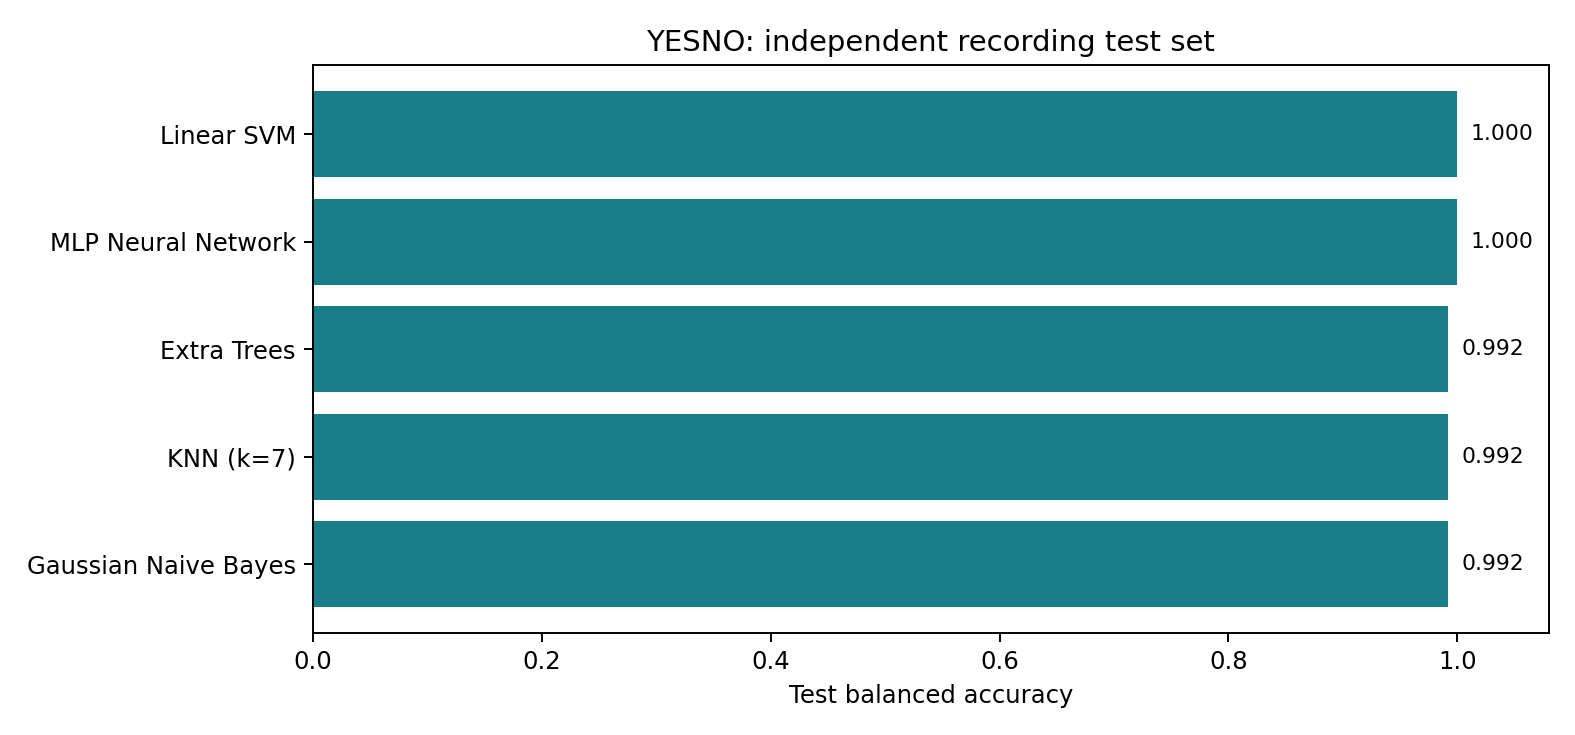

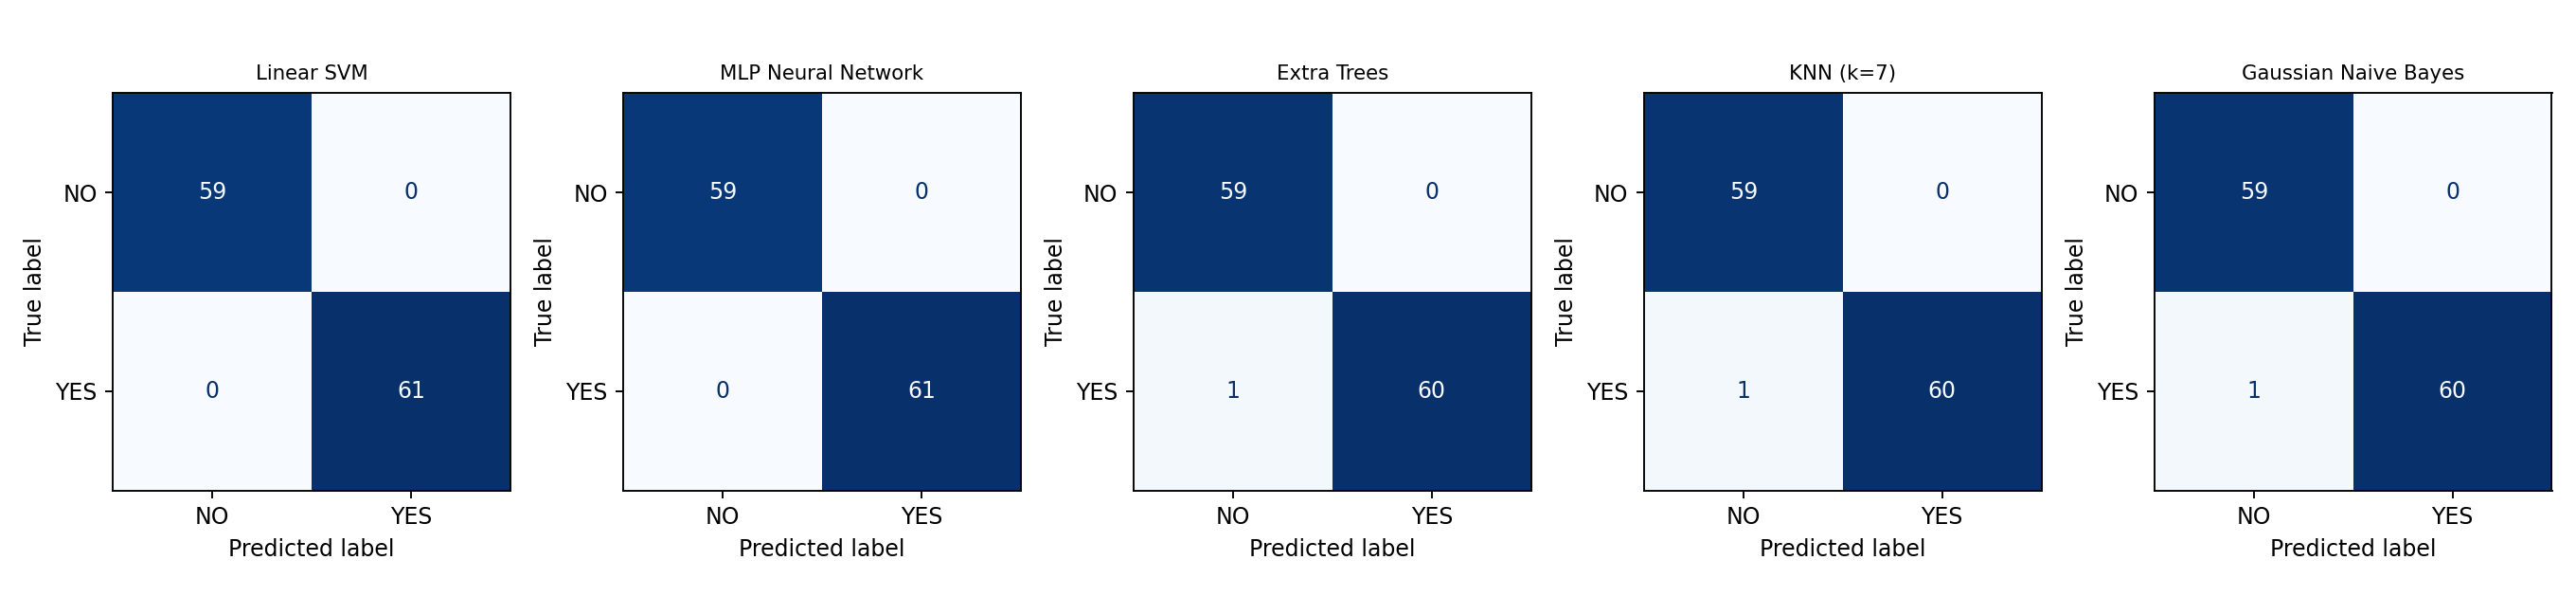

In [14]:
main()
display(pd.read_csv(ROOT/"results"/"model_comparison.csv"))
display(Image(filename=str(ROOT/"figures"/"model_comparison.png")))
display(Image(filename=str(ROOT/"figures"/"confusion_matrices.png")))


## 6. Testing the feature groups
I also evaluated a smaller feature set: log-frequency bands alone versus spectral descriptors alone. I used the same recording split and kept the model settings unchanged for this comparison. These results are exploratory and I did not use them to select a model before reporting its test accuracy.

,Feature set,Model,Test balanced accuracy
0,Log-frequency band statistics,Linear SVM,1.000000
1,Log-frequency band statistics,Extra Trees,0.991803
2,Spectral descriptors only,Linear SVM,0.934426
3,Spectral descriptors only,Extra Trees,0.925952
4,All 40 features,Linear SVM,1.000000
5,All 40 features,Extra Trees,0.991803


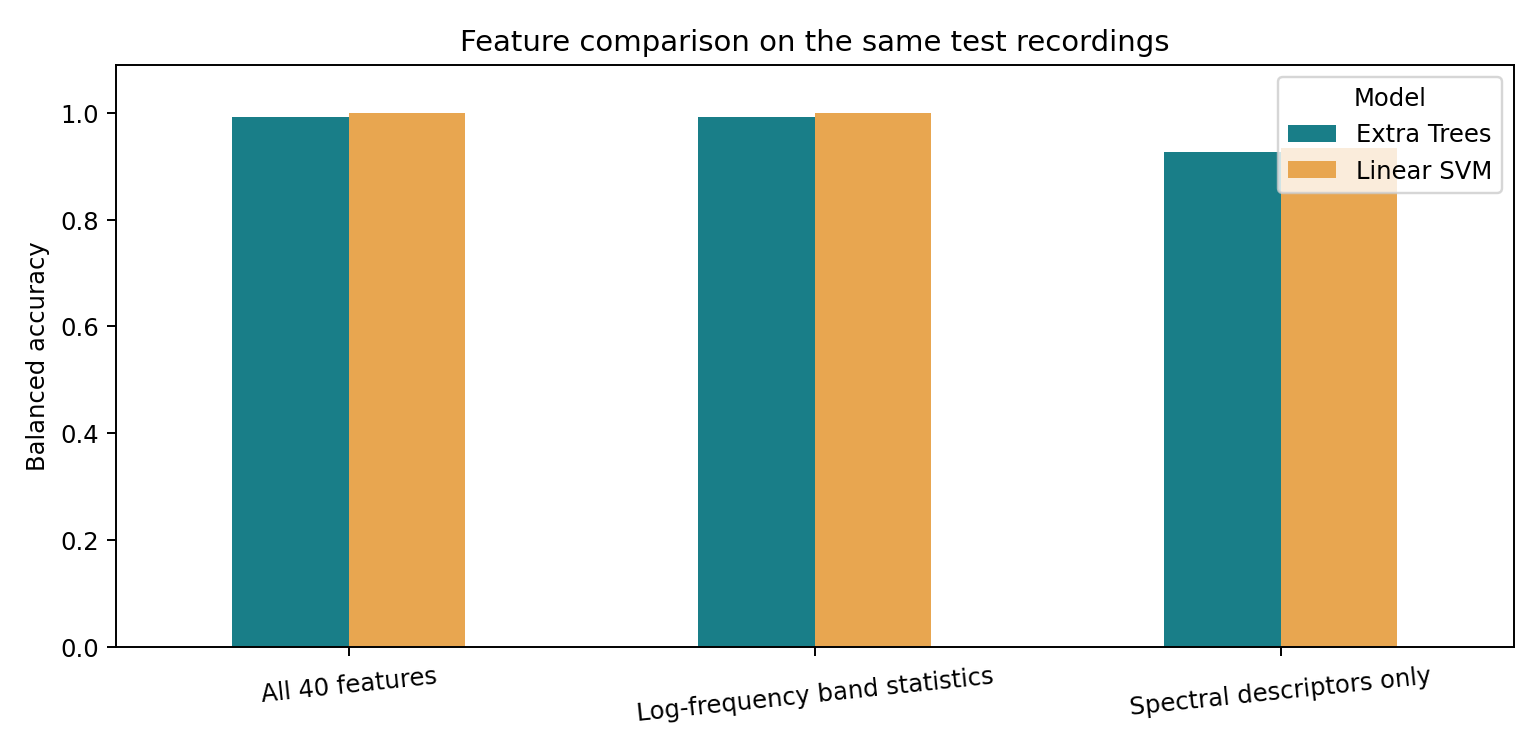

Excluded recordings:


,file,reason
0,0_1_0_1_0_0_0_0.wav,Only 7 energy peaks were detected


Sample segmentation review:


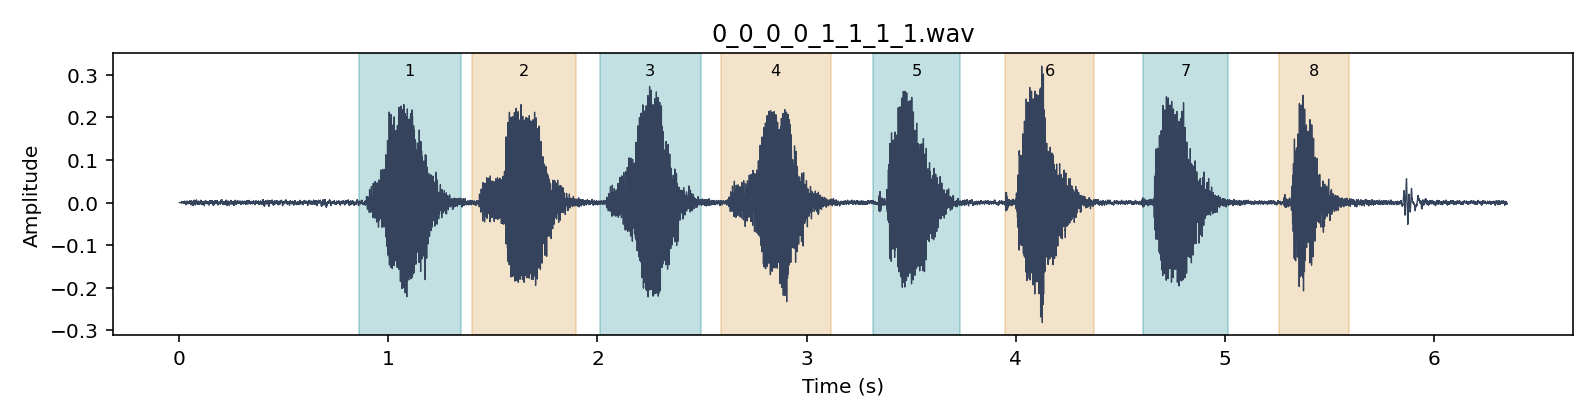

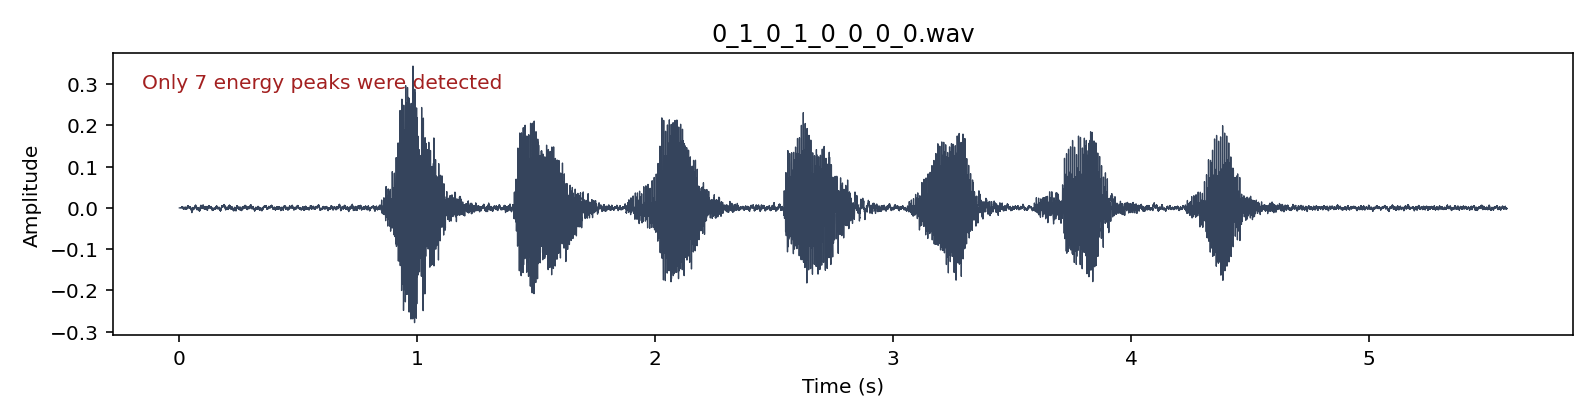

In [16]:
display(pd.read_csv(ROOT/"results"/"feature_ablation.csv"))
display(Image(filename=str(ROOT/"figures"/"feature_ablation.png")))
print("Excluded recordings:")
display(pd.read_csv(ROOT/"results"/"rejected_recordings.csv"))
print("Sample segmentation review:")
display(Image(filename=str(ROOT/"figures"/"segmentation_review"/"00.png")))
display(Image(filename=str(ROOT/"figures"/"segmentation_review"/"21.png")))


## 7. Discussion
In the completed run, I retained **59 recordings** (472 words) and excluded the recording `0_1_0_1_0_0_0_0.wav` because I detected only seven reliable energy peaks for its eight labels. The training set had **44 recordings** (352 words), and the independent test set had **15 recordings** (120 words).

The **linear SVM** and **MLP** classified every test word correctly. **Extra Trees**, **KNN**, and **Gaussian Naive Bayes** each made one error. The results are high because the recording conditions and speaker are very similar across files. These numbers do not establish performance for other speakers, languages or noisy recordings.

The feature experiment showed that the log-frequency band statistics alone reached the same test balanced accuracy as the combined 40 features for the two models used in that comparison. Spectral descriptors alone gave lower scores, which suggests that the frequency-distribution information was especially useful here.

I checked the word boundaries using the saved segmentation plots. This remains an energy-based approximation; I did not manually annotate or listen to every word in all recordings. I therefore report the excluded file and the limitations of this dataset rather than treating the high accuracy as a general speech-recognition result.

## References
1. PyTorch Audio: `torchaudio.datasets.YESNO` documentation: https://docs.pytorch.org/audio/stable/generated/torchaudio.datasets.YESNO.html
2. OpenSLR SLR1 (YESNO): https://www.openslr.org/1/
3. scikit-learn model selection: https://scikit-learn.org/stable/modules/cross_validation.html

## Environment versions

In [19]:
import sklearn, scipy
print("Python:",sys.version.split()[0])
print("PyTorch:",__import__("torch").__version__)
print("torchaudio:",torchaudio.__version__)
print("scikit-learn:",sklearn.__version__)
print("scipy:",scipy.__version__)


Python: 3.13.5
PyTorch: 2.10.0+cpu
torchaudio: 2.10.0+cpu
scikit-learn: 1.8.0
scipy: 1.17.0
